# Stochastic algorithms

*Beyond the exercises — chapter 9 of the scriptum.*

---

Every other notebook uses chance for **estimation**: we want a number (an integral, a probability, an
expectation) and random samples are the route to it. This notebook is about something else — about
chance as a **part of an algorithm** that is to deliver the answer to a completely non-probabilistic
question.

- **Primality testing**: a randomized algorithm that is allowed to be wrong, but only in one
  direction and only with a probability you choose
- **Simulated annealing**: how to find a good solution to an optimization problem by occasionally
  taking a deliberate step for the worse

What these have in common is that the randomness models nothing in the world. It is a **tool inside
the computation**.

In [1]:
import math
import random
import time

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results

## 1. Is it a prime?

Trial division up to $\sqrt n$ is reliable, but for numbers with hundreds of digits (which are exactly
the ones RSA needs) it is hopelessly slow. The randomized approach trades certainty for speed.

### Fermat's test and why it is not enough

Fermat's little theorem: if $n$ is a prime and $1 < a < n$, then

$$a^{n-1} \equiv 1 \pmod n.$$

We turn it around: if we find an $a$ for which the equality does **not** hold, then $n$ is certainly
composite. Such an $a$ is called a **witness** of compositeness. When the equality holds, $n$ is
"probably prime".

But there are composite numbers for which the equality holds for **all** $a$ coprime with $n$ —
**Carmichael numbers**, the smallest being $561 = 3\cdot 11\cdot 17$. Fermat's test is powerless
against them.

In [2]:
def fermat_test(n, tries=500):
    '''Fermat's test. Returns the fraction of WITNESSES among the bases COPRIME with n.

    Restricting to coprime bases is essential: a base sharing a divisor gives n away
    trivially (Euclid's algorithm suffices) and says nothing about the strength of Fermat's test.
    '''
    witnesses = tested = 0
    for _ in range(tries):
        a = random.randrange(2, n - 1)
        if math.gcd(a, n) != 1:
            continue
        tested += 1
        if pow(a, n - 1, n) != 1:
            witnesses += 1
    return witnesses / tested, tested


print(f"{'n':>9s} {'type':>24s} {'coprime bases':>15s} {'witnesses':>12s}")
for n, desc in ((97, "prime"), (561, "Carmichael (3·11·17)"), (1105, "Carmichael (5·13·17)"),
                (1729, "Carmichael (7·13·19)"), (1001, "composite (7·11·13)")):
    fraction, tested = fermat_test(n)
    print(f"{n:>9d} {desc:>24s} {tested:>15d} {fraction:>12.1%}")

        n                     type   coprime bases    witnesses
       97                    prime             500         0.0%
      561     Carmichael (3·11·17)             281         0.0%
     1105     Carmichael (5·13·17)             350         0.0%
     1729     Carmichael (7·13·19)             392         0.0%
     1001      composite (7·11·13)             355        88.5%


An ordinary composite number (1001) is given away by almost every base — the witnesses are around
90 %.

For the Carmichael numbers the number of witnesses is **exactly zero**. That is not "few", it is
nothing: every base coprime with $n$ satisfies the equality. Fermat's test is powerless against them
no matter how many times you run it. And there are infinitely many Carmichael numbers (Alford,
Granville and Pomerance, 1994).

### The Miller–Rabin test

The fix is to use more structure. Write $n - 1 = 2^s d$ with an odd $d$. If $n$ is an odd prime, then
for every $a$

$$a^d \equiv 1 \pmod n \qquad\text{or}\qquad a^{2^r d} \equiv -1 \pmod n \ \text{ for some } 0 \le r < s.$$

The reason: for a prime, $x^2 \equiv 1 \pmod n$ has only the solutions $x \equiv \pm 1$. For a
composite $n$ there are other square roots of one as well, and those are exactly what the test
reveals.

The key property: for a **composite** $n$ at least $3/4$ of all bases are witnesses. After $k$
independent tries the probability of error is at most $4^{-k}$ — and the error is **one-sided**:
"composite" is always true, "prime" can be a mistake.

In [3]:
def mr_witness(n, a):
    '''Is the base a a witness of the compositeness of n by the Miller–Rabin criterion?'''
    d, s = n - 1, 0
    while d % 2 == 0:
        d //= 2
        s += 1
    x = pow(a, d, n)
    if x == 1 or x == n - 1:
        return False
    for _ in range(s - 1):
        x = x * x % n
        if x == n - 1:
            return False
    return True


def miller_rabin(n, k=20):
    '''The Miller–Rabin test. "Composite" is certain, "prime" holds with probability >= 1 - 4^-k.'''
    if n < 2:
        return False
    for p in (2, 3, 5, 7, 11, 13, 17, 19, 23, 29, 31, 37):
        if n % p == 0:
            return n == p
    return not any(mr_witness(n, random.randrange(2, n - 1)) for _ in range(k))


def mr_witness_fraction(n, max_bases=2000):
    '''The fraction of witnesses among the bases 2..n-2 (for a composite n it must be at least 3/4).'''
    bases = range(2, min(n - 1, max_bases + 2))
    return sum(mr_witness(n, a) for a in bases) / len(bases)


print(f"{'n':>10s} {'type':>24s} {'Fermat witn.':>13s} {'M-R witn.':>11s}")
for n, desc in ((561, "Carmichael (3·11·17)"), (1105, "Carmichael (5·13·17)"),
                (1729, "Carmichael (7·13·19)"), (1001, "composite (7·11·13)"),
                (25326001, "strong pseudoprime*")):
    f_txt = f"{fermat_test(n)[0]:12.1%}" if n < 10**6 else f"{'—':>12s}"
    print(f"{n:>10d} {desc:>24s} {f_txt} {mr_witness_fraction(n):11.1%}")

print("\nthe bound from the theorem: for a composite n at least 75 % of bases are witnesses — every row satisfies it")
print("* 25 326 001 passes the Miller–Rabin test for the bases 2, 3 and 5 at once")

         n                     type  Fermat witn.   M-R witn.
       561     Carmichael (3·11·17)         0.0%       98.6%
      1105     Carmichael (5·13·17)         0.0%       97.5%
      1729     Carmichael (7·13·19)         0.0%       90.7%
      1001      composite (7·11·13)        87.2%       99.2%
  25326001      strong pseudoprime*            —       86.5%

the bound from the theorem: for a composite n at least 75 % of bases are witnesses — every row satisfies it
* 25 326 001 passes the Miller–Rabin test for the bases 2, 3 and 5 at once


The Carmichael numbers that Fermat's test could not recognize are exposed by Miller–Rabin with ease —
over 75 % of bases are witnesses, exactly as the theorem promises.

Now the thing randomization is done for: speed.

In [4]:
def trial_division(n):
    '''Deterministic division up to sqrt(n).'''
    if n < 2:
        return False
    if n % 2 == 0:
        return n == 2
    i = 3
    while i * i <= n:
        if n % i == 0:
            return False
        i += 2
    return True


print(f"{'prime':>18s} {'digits':>7s} {'trial division':>16s} {'Miller-Rabin':>14s}")
rate = None
for exp in (15, 25, 35, 45):
    n = 2 ** exp - 1
    while not miller_rabin(n):
        n -= 2
    t0 = time.perf_counter()
    miller_rabin(n, 20)
    t_mr = time.perf_counter() - t0
    if exp <= 35:                       # above 35 bits we would be waiting far too long
        t0 = time.perf_counter()
        trial_division(n)
        t_td = time.perf_counter() - t0
        rate = math.sqrt(n) / 2 / t_td       # divisions per second, measured
        td = f"{t_td * 1e3:13.1f} ms"
    else:
        td = f"{'(not measured)':>16s}"
    print(f"{n:>18} {len(str(n)):>7d} {td:>16s} {t_mr * 1e3:11.2f} ms")

t0 = time.perf_counter()
candidate = random.randrange(2**511, 2**512) | 1
while not miller_rabin(candidate, 25):
    candidate += 2
t_search = time.perf_counter() - t0

print(f"\nfound a 512-bit prime ({len(str(candidate))} digits) in {t_search:.2f} s")
print(f"probability of error at most 4^-25 = {4.0 ** -25:.1e}")
years = math.sqrt(candidate) / 2 / rate / (3600 * 24 * 365.25)
print("\ntrial division at the measured rate (" + format(rate, ",.0f").replace(",", " ") + " divisions/s)")
print(f"  would take on the order of 10^{math.log10(years):.0f} years on it   (the universe is 1.4·10^10 years old)")

             prime  digits   trial division   Miller-Rabin
             32749       5           0.0 ms        0.02 ms
          33554393       8           0.1 ms        0.03 ms
       34359738337      11           5.2 ms        0.11 ms
    35184372088777      14   (not measured)        0.15 ms

found a 512-bit prime (155 digits) in 0.06 s
probability of error at most 4^-25 = 8.9e-16

trial division at the measured rate (17 822 157 divisions/s)
  would take on the order of 10^62 years on it   (the universe is 1.4·10^10 years old)


The last line is the point of the whole randomization: we find a 512-bit prime in a fraction of a
second with a probability of error around $10^{-15}$ — smaller than the chance of a hardware fault.
Trial division on the same number would run for longer than the universe has existed.

The **one-sided error** is essential here. The algorithm never labels a prime as composite. It can
only declare a composite number to be prime, and that probability we can drive down as far as we like
by raising $k$. Such algorithms are called **Monte Carlo algorithms** — as opposed to **Las Vegas**
algorithms, which always return the correct answer but whose running time is random.

## 2. Simulated annealing

The second way to use chance inside an algorithm: **optimization**.

The travelling salesman problem: $n$ cities, find the shortest round trip through all of them. The
number of possibilities is $(n-1)!/2$, so for 60 cities about $10^{80}$ — trying them all is out of
the question.

### Why always going downhill is not enough

The natural idea: start from a random tour and repeatedly make small changes that shorten it. That is
called **hill climbing**. It gets stuck in the first **local** minimum — a configuration that no small
change improves, even though the global optimum is elsewhere.

### The Metropolis criterion

Simulated annealing escapes local minima by **occasionally accepting a deliberate worsening**. A
change of $\Delta E$ is accepted with probability

$$P = \begin{cases} 1, & \Delta E \le 0 \quad\text{(an improvement is always accepted)},\\[1mm] e^{-\Delta E / T}, & \Delta E > 0 \quad\text{(a worsening only sometimes)}. \end{cases}$$

The parameter $T$ is the **temperature**. At a high $T$ almost everything is accepted and the
algorithm wanders; at a low $T$ it behaves like a hill climber. The gradual cooling is the metaphor of
annealing metal: the hot phase explores, the cold one fine-tunes.

The acceptance probability is exactly where $\gamma \sim R(0,1)$ is needed — we accept when
$\gamma < e^{-\Delta E/T}$.

In [5]:
def random_cities(n):
    return [(random.random(), random.random()) for _ in range(n)]


def tour_length(tour, cities):
    return sum(math.dist(cities[tour[i]], cities[tour[i - 1]]) for i in range(len(tour)))


def delta_2opt(tour, cities, i, j):
    '''By how much the length changes when the stretch tour[i:j+1] is reversed. Four distances suffice.'''
    n = len(tour)
    a, b = cities[tour[i - 1]], cities[tour[i]]
    c, d = cities[tour[j]], cities[tour[(j + 1) % n]]
    return (math.dist(a, c) + math.dist(b, d)) - (math.dist(a, b) + math.dist(c, d))


def initial_temperature(n):
    '''Roughly half a typical edge of a good tour.

    For n points uniform in a square the optimal tour measures about 0.7*sqrt(n),
    so one edge is around 0.7/sqrt(n). A temperature of the order of one edge means
    that appreciable worsenings are accepted at the start.
    '''
    return 0.5 * 0.7 / math.sqrt(n)


def annealing(cities, steps=300_000, T0=None, T1=1e-3, hill_climb=False):
    '''Simulated annealing with 2-opt moves. hill_climb=True accepts improvements only.'''
    n = len(cities)
    T0 = initial_temperature(n) if T0 is None else T0
    tour = list(range(n))
    random.shuffle(tour)
    d = tour_length(tour, cities)
    best, best_tour = d, tour[:]
    history, temps = [], []
    for step in range(steps):
        T = T0 * (T1 / T0) ** (step / steps)        # geometric cooling
        i = random.randrange(1, n - 1)
        j = random.randrange(i + 1, n)
        dE = delta_2opt(tour, cities, i, j)
        if dE <= 0 or (not hill_climb and random.random() < math.exp(-dE / T)):
            tour[i:j + 1] = reversed(tour[i:j + 1])
            d += dE
            if d < best:
                best, best_tour = d, tour[:]
        if step % 500 == 0:
            history.append(d)
            temps.append(T)
    return best_tour, best, history, temps


N_CITIES, STEPS, RUNS = 60, 300_000, 6
cities = random_cities(N_CITIES)
initial = list(range(N_CITIES))
random.shuffle(initial)

# a fair comparison: the same number of steps and runs, and we compare averages
t0 = time.perf_counter()
res_ann = [annealing(cities, steps=STEPS) for _ in range(RUNS)]
t_ann = (time.perf_counter() - t0) / RUNS
res_hill = [annealing(cities, steps=STEPS, hill_climb=True)[1] for _ in range(RUNS)]

d_ann = [v[1] for v in res_ann]
tour_ann, _, hist_ann, temps = min(res_ann, key=lambda v: v[1])

print(f"{N_CITIES} cities, " + format(STEPS, ",").replace(",", " ") + f" steps per run, {RUNS} runs of each method")
print(f"initial temperature T0 = {initial_temperature(N_CITIES):.4f}\n")
print(f"{'method':22s} {'average':>9s} {'best':>10s} {'worst':>10s}")
print(f"{'random tour':22s} {tour_length(initial, cities):9.3f}")
print(f"{'hill climbing':22s} {sum(res_hill) / RUNS:9.3f} {min(res_hill):10.3f} {max(res_hill):10.3f}")
print(f"{'simulated annealing':22s} {sum(d_ann) / RUNS:9.3f} {min(d_ann):10.3f} {max(d_ann):10.3f}")
print(f"\nannealing is on average {(sum(res_hill) / sum(d_ann) - 1):.1%} better,")
print(f"and even its worst run ({max(d_ann):.3f}) beats hill climbing's average ({sum(res_hill) / RUNS:.3f});")
print(f"only hill climbing's luckiest run ({min(res_hill):.3f}) gets into the same range.")
print(f"time for one annealing run: {t_ann:.2f} s")

60 cities, 300 000 steps per run, 6 runs of each method
initial temperature T0 = 0.0452

method                   average       best      worst
random tour               30.173
hill climbing              6.773      6.489      6.971
simulated annealing        6.461      6.388      6.532

annealing is on average 4.8% better,
and even its worst run (6.532) beats hill climbing's average (6.773);
only hill climbing's luckiest run (6.489) gets into the same range.
time for one annealing run: 0.23 s


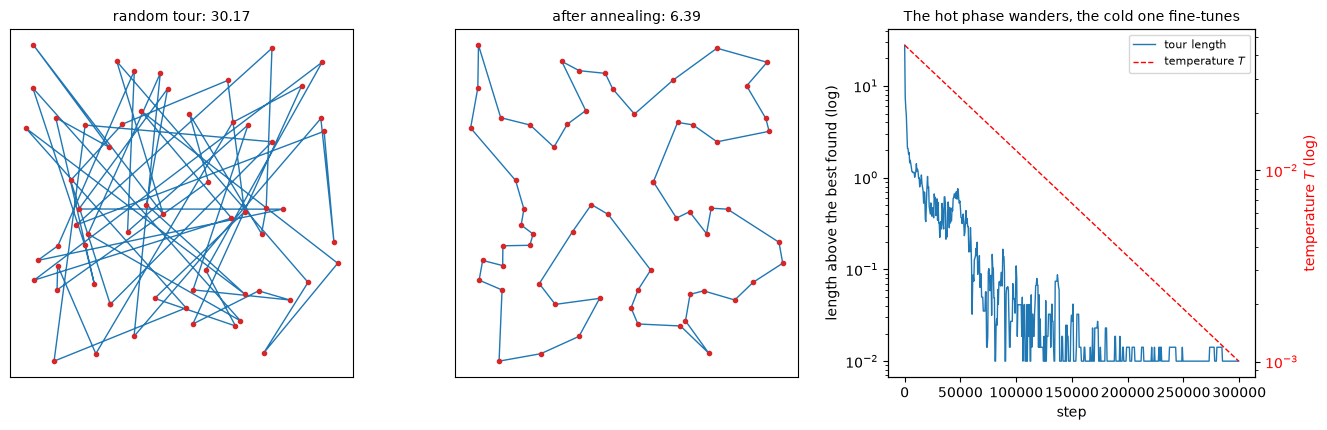

In [6]:
def draw(ax, tour, cities, title_):
    xs = [cities[k][0] for k in tour] + [cities[tour[0]][0]]
    ys = [cities[k][1] for k in tour] + [cities[tour[0]][1]]
    ax.plot(xs, ys, "-", lw=1, color="tab:blue")
    ax.plot(xs, ys, "o", ms=3, color="tab:red")
    ax.set_title(title_, fontsize=10)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])


fig = plt.figure(figsize=(13.5, 4.4))
ax = fig.add_subplot(1, 3, 1)
draw(ax, initial, cities, f"random tour: {tour_length(initial, cities):.2f}")
ax = fig.add_subplot(1, 3, 2)
draw(ax, tour_ann, cities, f"after annealing: {min(d_ann):.2f}")

ax = fig.add_subplot(1, 3, 3)
steps_ = [500 * i for i in range(len(hist_ann))]
ax.semilogy(steps_, [h - min(d_ann) + 1e-2 for h in hist_ann], lw=1, label="tour length")
ax.set_xlabel("step")
ax.set_ylabel("length above the best found (log)")
ax.set_title("The hot phase wanders, the cold one fine-tunes", fontsize=10)
ax2 = ax.twinx()
ax2.semilogy(steps_, temps, "r--", lw=1, label="temperature $T$")
ax2.set_ylabel("temperature $T$ (log)", color="r")
ax2.tick_params(axis="y", labelcolor="r")
handles = ax.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax.legend(handles, ["tour length", "temperature $T$"], fontsize=8, loc="upper right")

plt.tight_layout()
plt.show()

In the trace the two phases are visible: at first the temperature is high, the tour length fluctuates
wildly and the algorithm passes through markedly worse configurations as well. As the temperature
falls, the fluctuation dies away and the curve settles.

### The cooling rate matters

The theory says that with slow enough cooling ($T_k \sim 1/\log k$) annealing finds the global optimum
with a probability tending to one. But that is so slow that it is not used; in practice one cools
geometrically and settles for a good solution. Cooling too fast, however, degrades annealing into a
hill climber.

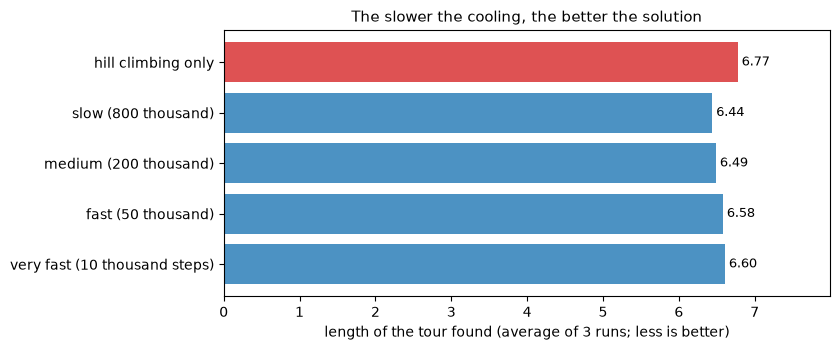

In [7]:
lengths = {}
for name, steps in (("very fast (10 thousand steps)", 10_000),
                    ("fast (50 thousand)", 50_000),
                    ("medium (200 thousand)", 200_000),
                    ("slow (800 thousand)", 800_000)):
    results = [annealing(cities, steps=steps)[1] for _ in range(3)]
    lengths[name] = sum(results) / len(results)

lengths["hill climbing only"] = sum(res_hill) / RUNS

fig, ax = plt.subplots(figsize=(8.5, 3.6))
names = list(lengths)
values = [lengths[n] for n in names]
colors = ["tab:red" if n == "hill climbing only" else "tab:blue" for n in names]
b = ax.barh(names, values, color=colors, alpha=0.8)
ax.bar_label(b, fmt="%.2f", padding=3, fontsize=9)
ax.set_xlabel("length of the tour found (average of 3 runs; less is better)")
ax.set_xlim(0, max(values) * 1.18)
ax.set_title("The slower the cooling, the better the solution", fontsize=11)
plt.tight_layout()
plt.show()

## Summary

| Concept | What to remember |
|---------|------------------|
| A Monte Carlo algorithm | fast; the answer can be wrong with a probability you choose |
| A Las Vegas algorithm | the answer is always correct, the running time is random |
| Fermat's test | $a^{n-1}\equiv 1$; it fails on Carmichael numbers (561, 1105, 1729) |
| Miller–Rabin | it uses the square roots of one as well; for a composite $n$, $\ge 3/4$ of bases are witnesses ⟹ error $\le 4^{-k}$ |
| One-sided error | "composite" is certain, "prime" is probable — and that is enough |
| Simulated annealing | accept a worsening of $\Delta E$ with probability $e^{-\Delta E/T}$ |
| Temperature | high = exploration, low = fine-tuning; cool gradually |
| Why it works | a hill climber gets stuck in a local minimum, annealing can jump out of it |

The main difference from the rest of the course: here the randomness **models nothing**. It is a tool
that replaces a computation which would otherwise take unbearably long.

### Try it yourself

1. Run Miller–Rabin with $k = 1$ on many composite numbers and measure how often it is wrong. Does the
   bound $1/4$ fit?
2. Find the smallest composite number that Miller–Rabin with the fixed bases $\{2, 3\}$ declares
   prime. (It is 1 373 653.)
3. Add a move other than 2-opt to the annealing — moving a single city elsewhere, say. Does the result
   improve?
4. Replace the geometric cooling with a linear one ($T_k = T_0(1 - k/K)$) and compare. Which is better
   and why?
5. Try annealing on a different problem: split $n$ numbers into two groups with equal sums (the
   partition problem). What is $\Delta E$ there and what is a move?
6. Set $T_0$ very low ($10^{-6}$, say) and verify that the annealing behaves exactly like a hill
   climber.